# 5. Butane: Rotation Energy Profiles

One of the easiest chemical **transformations** to model and explore in computational chemistry is **conformational** changes. We will start with potential energy profiles for **rotation**. We will build butane using the build tools in *wxMacMolPlt* and then submit the input file to *GAMESS* as an optimization calculation from this notebook.

No more symmetry (for now). If we want to rotate molecules around bonds, the symmetry will be **changing** with the rotation. Do consider that symmetry saved a lot of computational effort and should be considered carefully when using expensive methods. We will downgrade our **method** for optimizations to HF/3-21G.

## Learning Goals

In this exercise, we will accomplish the following…

1.	Use *MacMolPlt* to **build** molecules, generate input files and **interpret** results.
2.	**Freeze a coordinate** in a series of internal coordinates.
3.	**Change** the frozen coordinate and obtain the optimized structure and energy within that limitation.
4.	Learn **how to use** *Python* to generate a large series of input files with different values for the frozen coordinate and to **extract data** quickly from large numbers of files. We will run all these files from the notebook.
5.	With these methods we will create a **rotational energy profile** around a given bond in an alkane.

### Settings

Run this cell first. It loads the book's helper module, `gamess_tools.py`, which finds *GAMESS* using the location you set in `gamess_settings.py` on the [setup page](1_Setup.ipynb). The `.log` files are written into the `runs/ch5/` folder next to this notebook. That is the folder to look in when you open a result in *MacMolPlt*.

:::{note} Mac users: after a restart
macOS resets the shared-memory limits every time you restart. If a *GAMESS* job stops with a fatal error and the `.log` file shows `shmget returned an error`, set the limits again (see [Raise shared-memory limits](#shared-memory-limits) in [](1D-CompileInstruction2024.md)).
:::

In [1]:
# ===== SETTINGS =========================================================
# Your GAMESS location is set ONCE, in gamess_settings.py (next to this
# notebook). Edit that file, save it, and restart the kernel.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gamess_tools as gt

INPUTS = Path("inputs/ch5") # input files for this chapter
RUNS = Path("runs/ch5")     # where log files and new input files are written
RUNS.mkdir(parents=True, exist_ok=True)
gt.RUN_FOLDER = RUNS        # run_gamess() writes its files here

HARTREE_TO_KJMOL = 2625.5   # 1 hartree = 2625.5 kJ/mol
# ========================================================================

## Building Butane

Run *MacMolPlt*. Click on `Builder` &rarr; `Show Build Tools`. Choose carbon atoms and set the coordination number to 4 (four bonds to an sp3 carbon). Then click in the window to **build** the molecule, A carbon with four connections will appear. Then click on one of the connections to add a new carbon. When you have added all four carbon atoms, change the build tool to hydrogen and then click on the remaining connections to include bonds. In the end you will have a window that looks **like this** perhaps. 


```{figure} images/profiles_Picture1B.png
---
width: 450px
name: fig5-1
---
**MacMolPlt* window with the initial structure for butane.*
```

The structure in {numref}`fig5-1` is an initial **rough sketch**. Note that the terminal carbons are in *eclipsed* conformations. We will need to calculate the correct structure by creating an input file for *GAMESS*. Click on `Subwindow` &rarr; `Input Builder` and set the following **parameters**:

- In the `Control` menu section, set `Run Type` to `Optimization`. This will instruct *GAMESS* that we are doing a calculation to find the optimizes molecular geometry.
- In the `Basis` section, set `Basis Set` to `3-21G` and set `#D heavy atom polarizations functions` to `1`. This will run at the 3-21G
- In the `Data` section, set `Coord. Type` to `Z-Matrix` and set `# of Z-matrix variables` to `36` (14 atoms, so 3N – 6 = 36)
- In the `Misc. Prefs` section, check the `MolPlt` button. This will ensure that *GAMESS* outputs information in a format that can be read by the *MacMolPlt* application.
- Click on the `Edit and Save` button in the bottom of the `Input Builder` window. Then click on `Save As…` and save your file. Choose a name like `butane.inp`.

## Preparing to use *GAMESS*

We can now take the data file that was **written** out by *MacMolPlt* and use it as the input for *GAMESS*.

### The *GAMESS* Input File

**Open** the input file you just saved from *MacMolPlt* in a text editor. Any plain text editor will do. Microsoft *Visual Studio Code* is free and runs on all systems, and *JupyterLab* can open `.inp` files too.

A copy of the input file comes with this book as `inputs/ch5/butane.inp`. The cell below prints it. You should see the following text…



In [2]:
print((INPUTS / "butane.inp").read_text())

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=OPTIMIZE MAXIT=30 MULT=1 COORD=ZMT NZVAR=36 
    MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=20 $END
 $DATA 
Butane
C1
C
C   1    1.54000
C   2    1.54000  1  109.4712
C   1    1.54000  2  109.4712  3 -180.0000
H   1    1.14000  2  109.4712  4 -120.0000
H   1    1.14000  5  109.4712  2  120.0000
H   2    1.14000  1  109.4712  3 -120.0000
H   2    1.14000  7  109.4712  1  120.0000
H   3    1.14000  2  109.4712  8    0.0000
H   3    1.14000  9  109.4712  2  120.0000
H   3    1.14000  9  109.4712  10 120.0000
H   4    1.14000  1  109.4712  6   -0.0000
H   4    1.14000  12 109.4712  1  120.0000
H   4    1.14000  12 109.4712  13 120.0000
 $END
 $ZMAT IZMAT(1)=1,2,1, 
                1,3,2,  2,3,2,1, 
                1,4,1,  2,4,1,2,   3,4,1,2,3, 
                1,5,1,  2,5,1,2,   3,5,1,2,4, 
                1,6,1,  2,6,1,5, 

### Interpreting The Input File

The *GAMESS* input file **starts** off with essential settings and information in the `$CONTRL`, `$SYSTEM`, `$BASIS`, `$SCF` and `$STATPT` groups. Each group **ends** with `$END`. The settings within each group will be discussed where needed as we proceed, and detailed information is found in the [*GAMESS* documentation](https://www.msg.chem.iastate.edu/GAMESS/)

```{note}
All white space must be spaces, not tabs. And all lines that start with a \$ symbol must have that \$ symbol in the **second** column, not the first. Examine the above file and observe this fact.
```

The `$DATA` group contains the **description** of the molecule. The first line after the declaration of `$DATA` is the name of the molecule. You can change “Title” to “Butane” in the input builder if you wish.

The next line is the **symmetry**. We are not using symmetry, so the symmetry point group is declared to be *C<sub>1</sub>* (no symmetry). Using symmetry will greatly reduce the work of the calculation. We will ignore this useful idea for now.

The next line begins the **structure** of the molecule. We could use an *xyz* coordinate system but that is a block of numbers that can be difficult to interpret. We will use **internal coordinates** that describe each atoms relationship to another atom or atoms. This will make more sense when examined by the human eye and allows for greater control in setting up initial **geometries** and bond angles. The internal coordinate system that we will use is the *Z-matrix*

### The *Z-Matrix*


The *Z-matrix* for butane is composed of 14 lines for the 14 atoms. Here is the *Z-matrix* that was produced by *MacMolPlt*.

```text
C
C   1    1.54000
C   2    1.54000  1  109.4712
C   1    1.54000  2  109.4712  3 -180.0000
H   1    1.14000  2  109.4712  4 -120.0000
H   1    1.14000  5  109.4712  2  120.0000
H   2    1.14000  1  109.4712  3 -120.0000
H   2    1.14000  7  109.4712  1  120.0000
H   3    1.14000  2  109.4712  8    0.0000
H   3    1.14000  9  109.4712  2  120.0000
H   3    1.14000  9  109.4712  10 120.0000
H   4    1.14000  1  109.4712  6   -0.0000
H   4    1.14000  12 109.4712  1  120.0000
H   4    1.14000  12 109.4712  13 120.0000
```

Let us build the *Z-matrix* **line by line** using the example above.

The **first** atom in the matrix is a carbon and will be atom \#1 in the system. 

```text
C
```

The **second** atom is also a carbon and will be atom \#2. It is 1.54 Å away from that atom \#1. For two atoms, all we need to define the molecule is that single **bond length** value.

```text
C
C   1    1.54000
```

The **third** line is atom \#3. In this matrix it describes the third carbon atom in butane. It will be 1.54 Å from atom \#2 but now the distance no longer completely describes its position in the system. We know the **distance** from atom \#2 to this atom \#3, but we also now need a bond **angle** between atoms \#3, 2 and 1. In *sp<sup>3</sup>* carbons that angle is 109.4&deg; (120 for *sp<sup>2</sup>* and 180&deg; for *sp*).

```text
C
C   1    1.54000
C   2    1.54000  1  109.4712
```

The **fourth** line describes the fourth carbon atom, atom \#4. It is 1.54 Å from atom \#1. The bond angle between atoms \#4, 1, and 2 is 109.5&deg;. However, this is not enough information for four atoms. Three atoms are in a **plane**, by definition. Distance and angle will locate them all. However, a fourth atom is potentially outside of the plane of the first three. We now will add the angle to that fourth atom relative to the plane of the first three. This is a **dihedral angle**. In the case of our structure, the angle of the bond between atoms \#4 and \#1 relative to the plane of atoms \#1, 2 and 3 is 180&deg;. That is the same as saying that the plane described by \#1,2,3 is 180&deg; relative to the plane described by \#4,1,2.

This fourth line is very important. This dihedral angle is the **bond rotation** along the central C–C bond. This is the angle we will be using to rotate the centre bond of butane. {numref}`fig5-2A` shows the `Z-matrix` so far.

```text
C
C   1    1.54000
C   2    1.54000  1  109.4712
C   1    1.54000  2  109.4712  3  -180.0000
```

And that describes the following structures as we read each line…

```{figure} images/profiles_Picture2A.png
---
width: 450px
name: fig5-2A
---
*The first four lines of the *Z-matrix* are applied.*
```
 
By the **last line**, we will have constructed the following molecule. Note how the tenth line describes the bond, bond angle and dihedral angle for hydrogen atom #10 as shown in {numref}`fig5-2`.

```{figure} images/profiles_Picture2.png
---
width: 500px
name: fig5-2
---
*The 10th line of the *Z-matrix* is applied.*
```

We now have our molecule with the nuclei **positioned** in space (relative to each other via internal coordinates). The *GAMESS* program will place the nuclei in a Cartesian space and then calculate the locations of electrons from first principles using *ab initio* quantum mechanical calculations. We did tell *GAMESS* that all electrons were **paired** (no radicals) by using the `MULT=1` parameter and we did not specify a charge so that means there is no charge by **default**. 

We must always start **close** to the correct structure so that the calculation will snap to the closest lower energy minimum. If we **start** crazy, we might just **end up** crazy.

The final `$ZMAT` group describes a list of **descriptors** for every bond length, bond angle and dihedral angle. We will leave it be for now but will return to it soon.

## Finding Optimal Structure Using *GAMESS*

### Optimizing the Structure

Now we will feed the input file into the *GAMESS* program. One line of *Python* does this. `gt.run_gamess()` runs *GAMESS* with the number of processors set by `NCPUS` in `gamess_settings.py` (4 unless you change it). Your modern computer probably has 4 cores or more so we can always throw more power at the problem but this small calculation won't need any heavy iron. (Later in this chapter we will see that the number of processors can change the path an optimization takes.)

The job will **run** and produce an output file that will **contain** a description of the structure with the minimum overall energy. This might be the most stable structure for our molecule.

In [3]:
butane_log = gt.run_gamess(INPUTS / "butane.inp")

butane: finished normally (butane.log)


### The Output File

A **detailed** discussion of a *GAMESS* **output file** is presented in a later chapter where we repeat this exercise with butadiene. For now we will do things the **hard way**, one question at a time.

*GAMESS* writes its output to `runs/ch5/butane.log`. The log file has **thousands of lines** of text (assuming it didn't crash out with an error because I goofed up the input file). There is ultimately a line that states `EXECUTION OF GAMESS TERMINATED NORMALLY`. You could open the log file and **search** for the word `NORMALLY` in the text. The phrase should appear near the end of the file. If you find the word `ABNORMALLY` instead, then the run has crashed out. **Error information** will be in the file to troubleshoot. Crashes are almost always a problem with the input file. `gt.terminated_normally()` does this search for us.

In [4]:
print(len(butane_log.read_text().splitlines()), "lines in", butane_log.name)
print("terminated normally:", gt.terminated_normally(butane_log))

7869 lines in butane.log
terminated normally: True


The run exited in a controlled manner, but that does not mean that things went well. Let us examine the `butane.log` file. **Each step** of the search for an energy minimum involved calculating the **function** that describes the energy and then calculating the **derivative** of that function for each atom. The derivative is the gradient (a slope). If the gradient is zero then we are at a **stationary point** (either a maximum or minimum) and if the slope has a value then there is a **direction** downhill. *GAMESS* will calculate the change for each atom that will **follow** that gradient. The change will be applied to each atom and the new structure will be recalculated. This will repeat until the total gradient for the molecule has reached a very small value, indicating that we are at the **bottom** (or top!) of an energy surface. 

### Are We Done?

Each **step** is initiated in the text of the log file by the term `NSERCH`. If we **search** through the text file until the last time `NSERCH` appears we will find the **final** structural calculation and result. `gt.grep()` returns every line of a file that contains some text. `[-1]` picks the last one.

In [5]:
print(gt.grep("NSERCH:", butane_log)[-1])
for line in gt.grep("STATIONARY POINT", butane_log):
    print(line)

 NSERCH:  20  E=     -156.4322927357  GRAD. MAX=  0.0017274  R.M.S.=  0.0008046
          STATIONARY POINT LOCATION RUN
      ***** FAILURE TO LOCATE STATIONARY POINT, TOO MANY STEPS TAKEN *****


The **maximum** number of iterations was set to 20 in the input file (look for `NSTEP=20` in the `butane.inp` file). So we have **reached that maximum**, and a few lines later *GAMESS* gives us the news: `FAILURE TO LOCATE STATIONARY POINT, TOO MANY STEPS TAKEN`.

So no, we are **not done**. We need to set `NSTEP` to a higher number. Normally 20 steps is **enough** and we are likely close. Instead of editing `butane.inp` in a text editor, we let `gt.new_input()` write a copy, `runs/ch5/butane_30.inp`, with `NSTEP=20` changed to `NSTEP=30`.

In [6]:
butane30_inp = gt.new_input(INPUTS / "butane.inp", RUNS / "butane_30.inp",
                            replacements={"NSTEP=20": "NSTEP=30"})
butane30_log = gt.run_gamess(butane30_inp)

butane_30: finished normally (butane_30.log)


### Optimized Structure and Energy

The new output file is `runs/ch5/butane_30.log`. Let us look at the final line containing `NSERCH` and search for the verdict.

In [7]:
print(gt.grep("NSERCH:", butane30_log)[-1])
for line in gt.grep("EQUILIBRIUM GEOMETRY LOCATED", butane30_log):
    print(line)

 NSERCH:  28  E=     -156.4324667260  GRAD. MAX=  0.0000511  R.M.S.=  0.0000220
      ***** EQUILIBRIUM GEOMETRY LOCATED *****


We **reached the end** of the calculation before the maximum number of steps, and we see the line `EQUILIBRIUM GEOMETRY LOCATED`. So we now know that *GAMESS* has declared the calculation a **success**.

We can **open** the log file `runs/ch5/butane_30.log` in *MacMolPlt* and it will **display** the final structure shown in {numref}`fig5-3`. There is a **slider** at the bottom of the window that will show all the structures in the **journey** if you scrub it back and forth.

```{figure} images/profiles_Picture3.png
---
width: 450px
name: fig5-3
---
*The optimized structure as calculated by *GAMESS*.*
```

Immediately after the last `NSERCH` line is a series of data blocks containing the **structural information**. We can see the molecule described in Cartesian *xyz* coordinates. Following that, we see a block that describes all the **internal coordinates** (bond lengths, angles and torsions). There are 36 such coordinates and observe how each **corresponds** to an entry in the `$ZMAT` group at the end of the `butane.inp` input file. `gt.excerpt()` prints that block with its line numbers in the log file.

In [8]:
gt.excerpt(butane30_log, "INTERNAL COORDINATES", before=1, after=43)

 9070                       --------------------
 9071                       INTERNAL COORDINATES
 9072                       --------------------
 9073  
 9074                   - - ATOMS - -         COORDINATE      COORDINATE
 9075   NO.   TYPE    I  J  K  L  M  N        (BOHR,RAD)       (ANG,DEG)
 9076   ----------------------------------------------------------------
 9077     1 STRETCH   2  1                     2.9108112       1.5403351
 9078     2 STRETCH   3  2                     2.9117021       1.5408065
 9079     3 BEND      3  2  1                  1.9568844     112.1212165
 9080     4 STRETCH   4  1                     2.9117023       1.5408066
 9081     5 BEND      4  1  2                  1.9568839     112.1211878
 9082     6 TORSION   4  1  2  3              -3.1414618    -179.9925050
 9083     7 STRETCH   5  1                     2.0519138       1.0858261
 9084     8 BEND      5  1  2                  1.9050636     109.1521061
 9085     9 TORSION   5  1  2  4          

The sixth coordinate in the list describes the **torsion** around the central C—C bond (atoms 1 and 2) as described by the **dihedral angle** between the bonds to the other two carbons. See {numref}`fig5-4` for a diagram describing that coordinate. `gt.internal_coordinates()` reads the same table into a *Python* list, so we can pick out coordinate 6 directly (item 5, because *Python* counts from zero).

```{figure} images/profiles_Picture4.png
---
width: 500px
name: fig5-4
---
*The coordinate describing the central C–C bond torsion.*
```

In [9]:
kind, atoms, value = gt.internal_coordinates(butane30_log)[5]
print(kind, atoms, f"{value:.2f} degrees")

TORSION (4, 1, 2, 3) -179.99 degrees


We have found the **structure and energy** of the most stable conformer, the *anti* conformer.

## The Other Conformer

We started the calculation above with a structure that was already *anti* in conformation. It is no surprise that we then **settled** into a bottom of an energy well that describes that situation.

There is another **stable** conformer, the *gauche* conformer. In this conformer the torsion angle should be near 60&deg;. If we set the 4,1,2,3 bond torsion to 60&deg; in the input file and then run an optimization calculation, *GAMESS* will settle down into the **nearest** energy well, which should be the *gauche* conformer.

We **change** only the value for the 4,1,2,3 torsion angle (line 4 of the *Z-matrix*) and set `NSTEP=30`. The new file is `inputs/ch5/butane60.inp`, shown below.

In [10]:
print((INPUTS / "butane60.inp").read_text())

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=OPTIMIZE MAXIT=30 MULT=1 COORD=ZMT NZVAR=36 
    MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=30 $END
 $DATA 
Butane
C1
C
C   1    1.54000
C   2    1.54000  1  109.4712
C   1    1.54000  2  109.4712  3   60.0000
H   1    1.14000  2  109.4712  4 -120.0000
H   1    1.14000  5  109.4712  2  120.0000
H   2    1.14000  1  109.4712  3 -120.0000
H   2    1.14000  7  109.4712  1  120.0000
H   3    1.14000  2  109.4712  8    0.0000
H   3    1.14000  9  109.4712  2  120.0000
H   3    1.14000  9  109.4712  10 120.0000
H   4    1.14000  1  109.4712  6   -0.0000
H   4    1.14000  12 109.4712  1  120.0000
H   4    1.14000  12 109.4712  13 120.0000
 $END
 $ZMAT IZMAT(1)=1,2,1, 1,3,2, 2,3,2,1, 1,4,1, 2,4,1,2, 3,4,1,2,3, 1,5,1, 
    2,5,1,2, 3,5,1,2,4, 1,6,1, 2,6,1,5, 3,6,1,5,2, 1,7,2, 2,7,2,1, 3,7,2,1,3, 
    1,8,2, 2,8,2,7, 3,8,2,7,1, 1

In [11]:
butane60_log = gt.run_gamess(INPUTS / "butane60.inp")
print(gt.grep("NSERCH:", butane60_log)[-1])

butane60: finished normally (butane60.log)
 NSERCH:  23  E=     -156.4312439164  GRAD. MAX=  0.0000721  R.M.S.=  0.0000279


Searching for the last occurrence of `NSERCH` reveals that we have reached a **final structure** after 23 steps. Examining the first 10 lines of the **internal coordinates** of the result shows that the central C–C torsion is 67&deg;. This is very close to the expected value. It is not exactly 60&deg; because of the **steric size** of the methyl group.

In [12]:
gt.excerpt(butane60_log, "INTERNAL COORDINATES", before=1, after=14)

 7794                       --------------------
 7795                       INTERNAL COORDINATES
 7796                       --------------------
 7797  
 7798                   - - ATOMS - -         COORDINATE      COORDINATE
 7799   NO.   TYPE    I  J  K  L  M  N        (BOHR,RAD)       (ANG,DEG)
 7800   ----------------------------------------------------------------
 7801     1 STRETCH   2  1                     2.9158702       1.5430121
 7802     2 STRETCH   3  2                     2.9128559       1.5414171
 7803     3 BEND      3  2  1                  1.9742294     113.1150125
 7804     4 STRETCH   4  1                     2.9128532       1.5414156
 7805     5 BEND      4  1  2                  1.9742485     113.1161070
 7806     6 TORSION   4  1  2  3               1.1739939      67.2648974
 7807     7 STRETCH   5  1                     2.0521415       1.0859466
 7808     8 BEND      5  1  2                  1.9051708     109.1582460
 7809     9 TORSION   5  1  2  4          

## Communicating the Results

We can use *MacMolPlt* to create **images** of the two results. We will load in the log file of each. As an example we will use the most recent result stored as `runs/ch5/butane60.log`. I will use the mouse pointer to select the four carbon atoms. Then I will **display** the value of the dihedral angle by choosing `View` &rarr; `Annotations` &rarr; `Display Dihedral`. I then choose `File` &rarr; `Export…` and export the image as PNG. There are many settings here, feel free to explore. In the end I generated the two images shown in {numref}`fig5-5`.

```{figure} images/profiles_Picture5.png
---
width: 500px
name: fig5-5
---
*The optimized *gauche* and *anti* conformations*
```

## The Energy

The energy of each **structure** was calculated. The energy reported is the total electronic energy of the molecule, including the repulsion between the nuclei. It is measured from a zero where all the nuclei and electrons are infinitely far apart, so it is the energy released when these particles come together (per molecule). That is a huge number and it is not the "energy of atomization" (the energy released when neutral atoms combine), but only **differences** between such energies matter to us. The unit is the hartree.

One **hartree** (*E*<sub>h</sub>) is 4.3597 &times; 10<sup>−18</sup> J. When we **multiply** by Avogadro's number we get 2625.5 kJ/mol.

The **energies** for the final structures in our two calculations are the last `NSERCH` energies. `gt.optimization_steps()` reads every `NSERCH` line into a list of (step, energy, largest gradient, RMS gradient), and `[-1]` takes the last one.

In [13]:
E_anti = gt.optimization_steps(butane30_log)[-1][1]
E_gauche = gt.optimization_steps(butane60_log)[-1][1]
dE = E_gauche - E_anti
print(f"anti   E = {E_anti:.10f} hartree")
print(f"gauche E = {E_gauche:.10f} hartree")
print(f"difference = {dE:.6f} hartree = {dE * HARTREE_TO_KJMOL:.2f} kJ/mol")

anti   E = -156.4324667260 hartree
gauche E = -156.4312439164 hartree
difference = 0.001223 hartree = 3.21 kJ/mol


The difference is 0.001223 hartree. This comes out to 3.21 kJ/mol. The **literature** value is 3.8 kJ/mol, so even this low level of theory (3-21G) performed well.

## Freezing a Coordinate

Allowing the structure to **relax** to minimums at torsional angles of near 180&deg; (*anti*) and 60&deg; (*gauche*) merely requires **allowing** it to happen. But how do we optimize a structure for a maximum? The *syn* conformer and the *eclipsed* conformer are each **peaks** in energy. We can **freeze** the value for any of the coordinates in the `$ZMAT` group using the `IFREEZ` setting within the `$STATPT` group.

The sixth coordinate in the `$ZMAT` group is for the central C–C bond **torsion**. If we add the command `IFREEZ(1)=6` then the value of that **internal coordinate** will not be able to change. All the other bond lengths, angles and torsions will seek their lowest energy so we will hopefully find the lowest energy versions of the *syn* and *eclipsed* conformations.

We change the `4,1,2,3` torsion to 0&deg; (*syn*) and then lock the sixth coordinate in the `$ZMAT` group that **corresponds** to that internal coordinate. The new input file, `inputs/ch5/butane_scan_0.inp`, is shown below.

In [14]:
print((INPUTS / "butane_scan_0.inp").read_text())

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=OPTIMIZE MAXIT=30 MULT=1 COORD=ZMT NZVAR=36 
    MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=50 IFREEZ(1)=6 $END
 $DATA 
Butane
C1
C
C   1    1.54000
C   2    1.54000  1 109.4712
C   1    1.54000  2 109.4712   3    0.0000
H   1    1.14000  2 109.4712   4 -120.0000
H   1    1.14000  5 109.4712   2  120.0000
H   2    1.14000  1 109.4712   3 -120.0000
H   2    1.14000  7 109.4712   1  120.0000
H   3    1.14000  2 109.4712   8    0.0000
H   3    1.14000  9 109.4712   2  120.0000
H   3    1.14000  9 109.4712  10  120.0000
H   4    1.14000  1 109.4712   6   -0.0000
H   4    1.14000  12 109.4712  1  120.0000
H   4    1.14000  12 109.4712 13  120.0000
 $END
 $ZMAT IZMAT(1)=1,2,1, 1,3,2, 2,3,2,1, 1,4,1, 2,4,1,2, 3,4,1,2,3, 1,5,1, 
    2,5,1,2, 3,5,1,2,4, 1,6,1, 2,6,1,5, 3,6,1,5,2, 1,7,2, 2,7,2,1, 3,7,2,1,3, 
    1,8,2, 2,8,2,7, 3

In [15]:
scan0_log = gt.run_gamess(INPUTS / "butane_scan_0.inp")
for line in gt.grep("PRINCIPAL AXES", scan0_log):
    print(line)

butane_scan_0: FAILED, see /Users/blink/github/UsingGAMESSv2/runs/ch5/butane_scan_0.log
 UNABLE TO GENERATE PRINCIPAL AXES


The calculation **failed** because of the high symmetry of this *Z-matrix*. I found the error message `UNABLE TO GENERATE PRINCIPAL AXES` near the end of a short log file.

The **zero degree** torsion resulted in a situation where *GAMESS* was **unable** to take a guess at which atoms to place along the primary axis (the *z*-axis in most calculations). When this happens all we need to do is **mess up** the symmetry of the input file. We will **change** the last 120.0000 value in the *Z-matrix* to 119.0000 and see if that helps. `gt.new_input()` writes the changed copy, `runs/ch5/butane_scan_0b.inp`.

In [16]:
tweak = {"H   4    1.14000  12 109.4712 13  120.0000":
         "H   4    1.14000  12 109.4712 13  119.0000"}
scan0b_inp = gt.new_input(INPUTS / "butane_scan_0.inp", RUNS / "butane_scan_0b.inp",
                          replacements=tweak)
scan0b_log = gt.run_gamess(scan0b_inp)
print(gt.grep("NSERCH:", scan0b_log)[-1])

butane_scan_0b: finished normally (butane_scan_0b.log)
 NSERCH:  23  E=     -156.4228465418  GRAD. MAX=  0.0000585  R.M.S.=  0.0000204


It did help. *GAMESS* converts your *Z-matrix* into Cartesian *xyz* data for the calculation. If it cannot decide how your molecule relates to the three axes then it will choke. If you get an error like the above just tweak a few values to break symmetry. The line above shows the **final energy** reported.

I then set the **torsion angle** to 120&deg; (*eclipsed*) and submitted the calculation again. Once more `gt.new_input()` writes the file: the same tweak, plus 120.0000 in place of 0.0000 on line 4 of the *Z-matrix*. We search the log file for the final `NSERCH` line and again find an energy for the optimized **structure** with the C–C torsion frozen at 120&deg;.

In [17]:
tweak120 = dict(tweak)
tweak120["C   1    1.54000  2 109.4712   3    0.0000"] = "C   1    1.54000  2 109.4712   3  120.0000"
frozen120_inp = gt.new_input(INPUTS / "butane_scan_0.inp", RUNS / "butane_frozen_120.inp",
                             replacements=tweak120)
frozen120_log = gt.run_gamess(frozen120_inp)
print(gt.grep("NSERCH:", frozen120_log)[-1])

butane_frozen_120: finished normally (butane_frozen_120.log)
 NSERCH:  24  E=     -156.4267263463  GRAD. MAX=  0.0000884  R.M.S.=  0.0000234


## The Energy Profile

We now have points for **all four** identified conformers. If we use the *anti* conformer as the base, we can calculate the difference in energy to the two maximums.

In [18]:
conformers = {"anti": butane30_log, "gauche": butane60_log,
              "eclipsed (120)": frozen120_log, "syn (0)": scan0b_log}
for name, log in conformers.items():
    E = gt.optimization_steps(log)[-1][1]
    torsion = gt.internal_coordinates(log)[5][2]
    print(f"{name:15s} torsion = {abs(torsion):6.1f} deg   "
          f"E - E(anti) = {(E - E_anti) * HARTREE_TO_KJMOL:5.1f} kJ/mol")

anti            torsion =  180.0 deg   E - E(anti) =   0.0 kJ/mol
gauche          torsion =   67.3 deg   E - E(anti) =   3.2 kJ/mol
eclipsed (120)  torsion =  120.0 deg   E - E(anti) =  15.1 kJ/mol
syn (0)         torsion =    0.0 deg   E - E(anti) =  25.3 kJ/mol


The *syn* conformer is 25.3 kJ/mol higher in energy than the *anti* conformer and the *eclipsed* conformer is 15.1 kJ/mol higher.

We could use this information to **sketch** out the rotational energy profile. The line in {numref}`fig5-6` is just drawn in and has no mathematical value, although it's likely close to how the energy changes with torsion angle. Remember, we are using a low level of theory and are in **gas phase**, so accuracy will be low but the trend is clear.

```{figure} images/profiles_Picture6.png
---
width: 450px
name: fig5-6
---
*Rotational energy profile for butane.*
```

We can display images that represent the minimized structures for the *syn* and *eclipsed* conformers using *MacMolPlt* as we did above. See {numref}`fig5-7`.

```{figure} images/profiles_Picture7.png
---
width: 600px
name: fig5-7
---
*The calculated structure for the *anti*, *eclipsed*, *gauche*, and *syn* conformers.*
```

We can **repeat** these calculations again and again using **different values** for the 4,1,2,3 torsion. All it takes is typing and time.

Further down this page, and in the [workflow section](5_Rotation_Profiles_Workflow.ipynb), you will see ways to use the power of your computer and *Python* to enable these operations to be **done quickly**. Below is a plot of data points between zero and 180&deg;. I performed calculations at 5&deg; intervals. It took only minutes to **create** the 36 input files and submit them all. After a pause to brew a coffee, the jobs finished (it is a low cost level of theory – we could use basis sets that would result in run times of days on my little desktop computer). I then was able to **extract** the energies and get a **plot** in less than a minute of effort. See {numref}`fig5-8`.

```{figure} images/profiles_Picture8.png
---
width: 450px
name: fig5-8
---
*Rotational energy profile for butane at 3-21G level.*
```

### Higher Level Theory

For fun I set up a **calculation** for a scan of the central C–C torsion using the 6-311G(d,p)++ level of theory. I selected the 6-311G basis set. Then I set the `# D heavy atom polarization functions` to 1 and the `# light atom polarization functions` to 1, and turned on the diffuse functions. {numref}`fig5-9` is a plot of the 3-21G level compared to the 6-311G(d,p)++ level.

```{figure} images/profiles_Picture9.png
---
width: 450px
name: fig5-9
---
*Rotational energy profile for butane at 3-21G (black) and 6-311G(d,p)++ level (orange).*
```

You can see that they are very similar. The **torsion angle** for the *gauche* conformer was calculated to be 65&deg; when using the 6-311G(d,p)++ basis set (compared to 67&deg;). The **energy profile** is very similar. When using 1st and 2nd row elements with no charges or strained bonds, the 3-21G basis set gives good results.

## Using *Python* to Read Log Files

*GAMESS* writes its results as long text files. To **extract** the important bits of information we use two functions from the helper module `gamess_tools.py`: `gt.grep()` searches a file and `gt.substitute()` writes a new file with some text replaced. The code is short enough to read.

### Extracting Information

We will now extract just the **lines that we want** from the large log file. `gt.grep()` reads the file line by line and returns only the lines that contain a given text string. The lines that contain `NSERCH` hold the calculated energy and the step number for each optimization step. Here are the first nine of them.

In [19]:
nserch_lines = gt.grep("NSERCH", butane60_log)
print(len(nserch_lines), "lines contain NSERCH")
for line in nserch_lines[:9]:
    print(line)

72 lines contain NSERCH
 BEGINNING GEOMETRY SEARCH POINT NSERCH=   0 ...
          NSERCH=  0     ENERGY=    -156.3976725
 NSERCH:   0  E=     -156.3976725172  GRAD. MAX=  0.0342576  R.M.S.=  0.0202008
 BEGINNING GEOMETRY SEARCH POINT NSERCH=   1 ...
          NSERCH=  1     ENERGY=    -156.4194365
 NSERCH:   1  E=     -156.4194365451  GRAD. MAX=  0.0160489  R.M.S.=  0.0065193
 BEGINNING GEOMETRY SEARCH POINT NSERCH=   2 ...
          NSERCH=  2     ENERGY=    -156.4205248
 NSERCH:   2  E=     -156.4205247564  GRAD. MAX=  0.0115845  R.M.S.=  0.0049553


You can see that this is **every** line in the file that includes the string `NSERCH`. I want just the lines that **contain** the energy and the gradient. So I keep only the lines that also contain `GRAD`.

In [20]:
grad_lines = [line for line in nserch_lines if "GRAD" in line]
for line in grad_lines:
    print(line)

 NSERCH:   0  E=     -156.3976725172  GRAD. MAX=  0.0342576  R.M.S.=  0.0202008
 NSERCH:   1  E=     -156.4194365451  GRAD. MAX=  0.0160489  R.M.S.=  0.0065193
 NSERCH:   2  E=     -156.4205247564  GRAD. MAX=  0.0115845  R.M.S.=  0.0049553
 NSERCH:   3  E=     -156.4217940327  GRAD. MAX=  0.0034421  R.M.S.=  0.0014419
 NSERCH:   4  E=     -156.4218684209  GRAD. MAX=  0.0028384  R.M.S.=  0.0011098
 NSERCH:   5  E=     -156.4219451020  GRAD. MAX=  0.0016161  R.M.S.=  0.0006247
 NSERCH:   6  E=     -156.4219994464  GRAD. MAX=  0.0012812  R.M.S.=  0.0005136
 NSERCH:   7  E=     -156.4220535294  GRAD. MAX=  0.0025621  R.M.S.=  0.0008132
 NSERCH:   8  E=     -156.4221827561  GRAD. MAX=  0.0034990  R.M.S.=  0.0011274
 NSERCH:   9  E=     -156.4225638258  GRAD. MAX=  0.0021031  R.M.S.=  0.0009366
 NSERCH:  10  E=     -156.4186389862  GRAD. MAX=  0.0111699  R.M.S.=  0.0054515
 NSERCH:  11  E=     -156.4220148254  GRAD. MAX=  0.0057583  R.M.S.=  0.0027684
 NSERCH:  12  E=     -156.4239720465  GR

To make a graph of the energy and the gradient as we go through the steps we need numbers, not lines of text. `gt.optimization_steps()` splits each of these lines into numbers, ready for a **pandas dataframe**. The energy in the **result table** is in hartree, a unit common in computational chemistry. We will convert to kJ/mol, relative to the final energy.

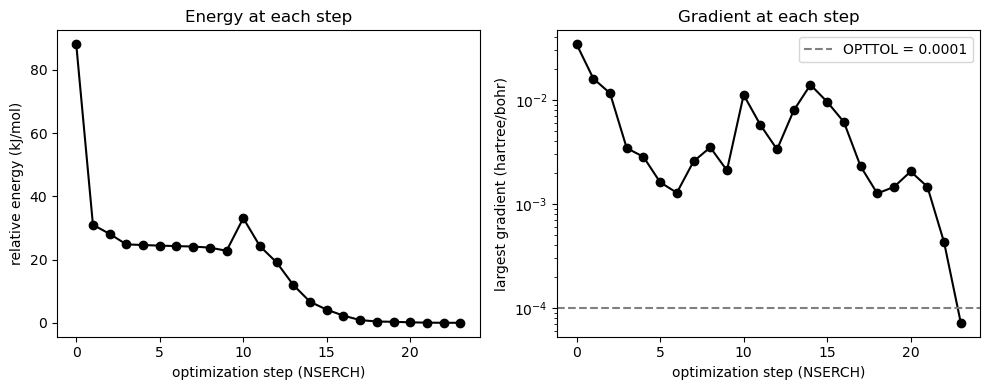

In [21]:
steps = pd.DataFrame(gt.optimization_steps(butane60_log),
                     columns=["NSERCH", "Energy", "GradMax", "RMS"])
steps["DeltaE"] = (steps["Energy"] - steps["Energy"].iloc[-1]) * HARTREE_TO_KJMOL

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(steps["NSERCH"], steps["DeltaE"], "ko-")
ax1.set(xlabel="optimization step (NSERCH)", ylabel="relative energy (kJ/mol)",
        title="Energy at each step")
ax2.plot(steps["NSERCH"], steps["GradMax"], "ko-")
ax2.set(xlabel="optimization step (NSERCH)", ylabel="largest gradient (hartree/bohr)",
        title="Gradient at each step", yscale="log")
ax2.axhline(0.0001, color="gray", ls="--", label="OPTTOL = 0.0001")
ax2.legend()
plt.tight_layout()
plt.show()

The energy **changes** quickly in the first few steps and then we keep making small changes until the *GAMESS* program halted the optimization when the largest gradient fell below `OPTTOL` (the dashed line). There was one phase where the process found a **steeper** path to the finish line. It's like going down a ski hill. You will always follow the **steepest** line from where you are standing, not always the best line. And you will encounter trees occasionally.

Instead of **searching** through the output file for the energy and gradient at each step, we used *Python* to extract the lines that we needed automatically.

### Making Many Similar Files

We can use *Python* to quickly produce a series of files for the **scan** of the torsion coordinate for the central C–C bond of butane.

First I will create a **new version** of the input file that we have been using and I will replace the value for the frozen torsion coordinate with the string `NUMBER`. I also set `NSTEP=1000`, so that no job runs out of steps. Below is the new input file, `inputs/ch5/butane-SCAN.inp`.

In [22]:
scan_template = INPUTS / "butane-SCAN.inp"
print(scan_template.read_text())

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=OPTIMIZE MAXIT=30 MULT=1 COORD=ZMT NZVAR=36 
    MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=1000 IFREEZ(1)=6 $END
 $DATA 
Butane
C1
C
C   1    1.54000
C   2    1.54000  1 109.4712
C   1    1.54000  2 109.4712   3   NUMBER
H   1    1.14000  2 109.4712   4 -120.0000
H   1    1.14000  5 109.4712   2  120.0000
H   2    1.14000  1 109.4712   3 -120.0000
H   2    1.14000  7 109.4712   1  120.0000
H   3    1.14000  2 109.4712   8    0.0000
H   3    1.14000  9 109.4712   2  120.0000
H   3    1.14000  9 109.4712  10  120.0000
H   4    1.14000  1 109.4712   6   -0.0000
H   4    1.14000  12 109.4712  1  120.0000
H   4    1.14000  12 109.4712 13  119.0000
 $END
 $ZMAT IZMAT(1)=1,2,1, 1,3,2, 2,3,2,1, 1,4,1, 2,4,1,2, 3,4,1,2,3, 1,5,1, 
    2,5,1,2, 3,5,1,2,4, 1,6,1, 2,6,1,5, 3,6,1,5,2, 1,7,2, 2,7,2,1, 3,7,2,1,3, 
    1,8,2, 2,8,2,7, 

The *Python* cell below writes one file for each angle. `range(0, 181, 10)` makes the list of numbers 0, 10, … 180 that the `for` loop walks through, `f"{angle:03d}"` writes each with three digits, and `gt.substitute()` copies the template and **replaces** `NUMBER` with the angle. The angle is also **appended** to the name of the new file. You can change the template name and the values in the series to suit your own scan.

In [23]:
scan_inputs = []
for angle in range(0, 181, 10):
    new_file = RUNS / f"butane-SCAN_{angle:03d}.inp"
    gt.substitute(scan_template, new_file, {"NUMBER": f"{angle:03d}"})
    scan_inputs.append(new_file)
print([f.name for f in scan_inputs])

['butane-SCAN_000.inp', 'butane-SCAN_010.inp', 'butane-SCAN_020.inp', 'butane-SCAN_030.inp', 'butane-SCAN_040.inp', 'butane-SCAN_050.inp', 'butane-SCAN_060.inp', 'butane-SCAN_070.inp', 'butane-SCAN_080.inp', 'butane-SCAN_090.inp', 'butane-SCAN_100.inp', 'butane-SCAN_110.inp', 'butane-SCAN_120.inp', 'butane-SCAN_130.inp', 'butane-SCAN_140.inp', 'butane-SCAN_150.inp', 'butane-SCAN_160.inp', 'butane-SCAN_170.inp', 'butane-SCAN_180.inp']


Nineteen files will be **created** with values written into the 4,1,2,3 torsion coordinate from 0 to 180 degrees. **Examine** any of the new files in the `runs/ch5/` folder and see that this is true. Then run them all. A `for` loop runs them one after the other. This takes a few minutes, because some of the jobs need hundreds of steps. With `rerun=False` the jobs that already have a finished log file are skipped, so you can run the cell again after an interruption.

In [24]:
scan_logs = [gt.run_gamess(inp, rerun=False) for inp in scan_inputs]

butane-SCAN_000: using existing butane-SCAN_000.log (rerun=True to run again)
butane-SCAN_010: using existing butane-SCAN_010.log (rerun=True to run again)
butane-SCAN_020: using existing butane-SCAN_020.log (rerun=True to run again)
butane-SCAN_030: using existing butane-SCAN_030.log (rerun=True to run again)
butane-SCAN_040: using existing butane-SCAN_040.log (rerun=True to run again)
butane-SCAN_050: using existing butane-SCAN_050.log (rerun=True to run again)
butane-SCAN_060: using existing butane-SCAN_060.log (rerun=True to run again)
butane-SCAN_070: using existing butane-SCAN_070.log (rerun=True to run again)
butane-SCAN_080: using existing butane-SCAN_080.log (rerun=True to run again)
butane-SCAN_090: using existing butane-SCAN_090.log (rerun=True to run again)
butane-SCAN_100: using existing butane-SCAN_100.log (rerun=True to run again)
butane-SCAN_110: using existing butane-SCAN_110.log (rerun=True to run again)
butane-SCAN_120: using existing butane-SCAN_120.log (rerun=True 

We now have **nineteen output files**. We need the final energy **from each file**. `gt.optimization_steps(log)[-1]` gives us the last `NSERCH` line of a log file, already split into numbers. We collect one row per file into a *pandas* dataframe.

In [25]:
rows = []
for angle, log in zip(range(0, 181, 10), scan_logs):
    step, energy, grad_max, rms = gt.optimization_steps(log)[-1]
    rows.append({"Torsion": angle, "NSERCH": step, "Energy": energy,
                 "GradMax": grad_max, "RMS": rms,
                 "Converged": grad_max < 0.0001})
scan = pd.DataFrame(rows)
display(scan)

,Torsion,NSERCH,Energy,GradMax,RMS,Converged
0,0,23,-156.422847,0.000058,0.000020,True
1,10,18,-156.423373,0.000093,0.000025,True
2,20,16,-156.424789,0.000079,0.000027,True
3,30,16,-156.426702,0.000039,0.000015,True
4,40,19,-156.428643,0.000077,0.000026,True
5,50,18,-156.430185,0.000024,0.000010,True
6,60,23,-156.431062,0.000068,0.000021,True
7,70,25,-156.431217,0.000034,0.000013,True
8,80,24,-156.430689,0.000099,0.000030,True
9,90,26,-156.429574,0.000049,0.000016,True


Look at the `NSERCH` and `Converged` columns. Most jobs finished in about 20 steps, but three of them (100&deg;, 130&deg; and 160&deg;) wandered for hundreds of steps. All three eventually found their way home: the `Converged` column is `True` for every angle, because `NSTEP=1000` gave them enough room.

When I first ran this scan the 100&deg; job **failed** to find a result: after 1000 steps it still had a large gradient and the energy was still high. When I changes the number of processors alocated to the job, it converged after 272 steps. Small differences in the computer can result in different rounding errors in 64-bit numbers. The same input file does not always take the same path.  

We could manually **check that input file** and perhaps change a few values to see if that helps. However, we have lots of points, so we could just drop an unconverged point from the data set. That is what the plot below does: only converged points are used.

We can load a log file into *MacMolPlt* and **scrub** along the minimization **path**. We can also **plot** the energy and gradients within *MacMolPlt*. Seek and you will find.

(processors-convergence)=
### Same Input, Different Result: The Number of Processors

When this notebook was run again, the 130&deg; job did something worrying. We ran the **same** input file on the **same** computer many times, changing only the number of processors (`ncpus` in `gt.run_gamess()`):

| Processors | Runs | Steps (`NSERCH`) | Outcome |
|:---:|:---:|:---:|:---|
| 1 | 4 | 262 every time | converged every time, identical energy to 10 decimal places |
| 2 | 2 | 228 and 1000 | one converged, one **failed** |
| 4 | 7 | 250 to 368, and 1000 twice | five converged, two **failed** |
| 8 | 2 | 188 and 232 | both converged |

A failed run used all of its `NSTEP=1000` steps and stopped with the largest gradient near 0.0057, about 57 times larger than `OPTTOL`. Its "final" energy was &minus;156.42380 hartree instead of &minus;156.42711 hartree, about **8.5 kJ/mol too high**. On the energy profile that would appear as a bump at 130&deg; that has nothing to do with the chemistry of butane.

Why would the number of processors matter? When *GAMESS* runs in **parallel**, the work of calculating the energy and gradient is divided among the processors and the pieces are added together at the end. Computers store numbers with a limited number of digits, so adding the same numbers in a different order can change the last digit. With several processors the order changes from run to run; with one processor it is always the same. Usually these differences are far too small to matter. However, this optimization is a long, difficult walk across a very flat energy surface, and a tiny difference early on can send it down a different path. Most paths reach the minimum. Occasionally one stalls. The other slow jobs (100&deg; and 160&deg;) converged every time we tried, but they needed anywhere from about 200 to 700 steps depending on the run.

```{important}
**Check your log files carefully.** The failed runs still ended with `EXECUTION OF GAMESS TERMINATED NORMALLY`, and `gt.run_gamess()` reported "finished normally". That message only means that the program did not crash. It does **not** mean the answer is right.

For every optimization, check that:

- the log file contains `EQUILIBRIUM GEOMETRY LOCATED`;
- the largest gradient (`GRAD. MAX`) in the last step is below `OPTTOL`;
- the number of steps (`NSERCH`) is well below the `NSTEP` limit;
- the result looks sensible next to its neighbours. A point that sits well above the smooth profile is a warning sign.

If a job fails, run it again. A different number of processors, or a slightly different starting structure, may be all it needs. If you need a calculation to give exactly the same numbers every time, run it on one processor, and always **record** how many processors you used.
```

The cell below checks every scan log for the `EQUILIBRIUM GEOMETRY LOCATED` message. Each job should say `True`.

In [26]:
for angle, log in zip(range(0, 181, 10), scan_logs):
    located = len(gt.grep("EQUILIBRIUM GEOMETRY LOCATED", log)) > 0
    print(f"{angle:3d} degrees   {log.name:22s} equilibrium geometry located: {located}")

  0 degrees   butane-SCAN_000.log    equilibrium geometry located: True
 10 degrees   butane-SCAN_010.log    equilibrium geometry located: True
 20 degrees   butane-SCAN_020.log    equilibrium geometry located: True
 30 degrees   butane-SCAN_030.log    equilibrium geometry located: True
 40 degrees   butane-SCAN_040.log    equilibrium geometry located: True
 50 degrees   butane-SCAN_050.log    equilibrium geometry located: True
 60 degrees   butane-SCAN_060.log    equilibrium geometry located: True
 70 degrees   butane-SCAN_070.log    equilibrium geometry located: True
 80 degrees   butane-SCAN_080.log    equilibrium geometry located: True
 90 degrees   butane-SCAN_090.log    equilibrium geometry located: True
100 degrees   butane-SCAN_100.log    equilibrium geometry located: True
110 degrees   butane-SCAN_110.log    equilibrium geometry located: True
120 degrees   butane-SCAN_120.log    equilibrium geometry located: True
130 degrees   butane-SCAN_130.log    equilibrium geometry locate

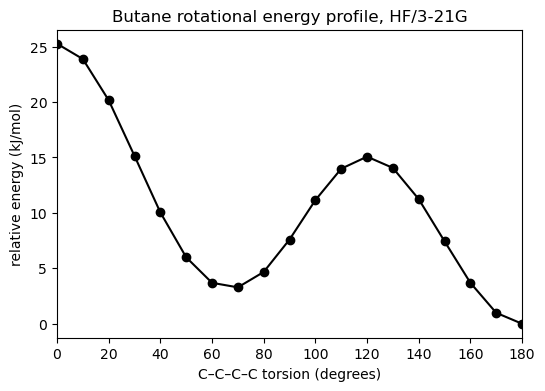

In [27]:
good = scan[scan["Converged"]]
E_min = good["Energy"].min()

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(good["Torsion"], (good["Energy"] - E_min) * HARTREE_TO_KJMOL, "ko-")
ax.set(xlabel="C–C–C–C torsion (degrees)", ylabel="relative energy (kJ/mol)",
       title="Butane rotational energy profile, HF/3-21G", xlim=(0, 180))
plt.show()

The rotational energy profile for butane behaves as expected. The [next section](5_Rotation_Profiles_Workflow.ipynb) repeats the whole scan step by step with a slightly different input file, and the [data section](5_Rotation_Profiles_Workflow_Data.ipynb) after it shows how to make a publication-quality plot.

## Summary

We used *MacMolPlt* to **build** a model of butane and export an initial input file for an optimization calculation. We **optimized** the structure for the *anti* conformation and found the *gauche* conformation by starting with an initial structure that was **near** that conformation. Thus we located the **global** minimum and a **local** minimum on the **rotational energy surface**.

Then we edited the file to **freeze** the coordinate that corresponded to the central C–C **bond rotation** and set the internal coordinate for that **torsion** to 0&deg; and 120&deg; to find the energy of the *syn* conformation and an *eclipsed* conformation. With this, we have the important parts of the rotational energy profile.

We learned how to use *Python* to **extract** information from large text files and from multiple text files and we learned how to **create** multiple input files using an **automated** process.

We examined the **format** of the *Z-matrix* in detail. We used the **internal coordinates** to easily create the series of input files for the rotational coordinate scan. Using *Python*, we created many input files with frozen torsion coordinates to create a rotational energy profile. We ran the files as a **batch job** from a `for` loop. We extracted the energy from these files and plotted the complete rotational energy profile.

## Exercise

Read the accompanying discussion and then try the following exercises.

### The Activities

**Construct** ethane, propane, butane, 2-methylbutane using *MacMolPlt*. **Export** input files for *GAMESS* with *Z-matrices* and using the `$ZMAT` group for declaring internal coordinates.

**Identify** all likely minima and maxima along the **rotational energy surface** using the central C–C torsion coordinate of each molecule. **Calculate** the HF/3-21G energy for optimized structures at these points in the coordinate. Use frozen coordinates (or symmetry) for the energy maxima. **Create** a table with the energies and torsion angles for all your calculations (relative to the global minimum in each) with units in kJ/mol and degrees.

Using *Python* (or brute force) **generate** input files for rotational energy scans of these molecules. Produce a **plot** of energy vs. angle to create a **visual representation** of the rotational energy profile of each molecule. Try placing all four profiles on the same plot for comparison.

```{tip}
Copy the scan cells above. Put `NUMBER` in place of the torsion value in your own template, change the template name and the file names, and change the `range()` if you want a finer scan.
```

### The Report

Present a ONE PAGE **document** with the table of angles and energies for maxima and minima that you generated. Include the plot of the entire rotational energy profile and **comment** if it fits with your table.

If you brute forced the operation, please **report the time** it took to create all the files and extract the energy data from each result file. If you used *Python*, please **report the time** as well. The table and plot must be professional in appearance.

## AI Statement

This page was converted from the original Markdown page `5_Rotation_Profiles.md` to a *Jupyter* notebook with the help of Claude (Anthropic), following the author's instructions.

- **Original text kept (about 75 %).** The introduction, the *MacMolPlt* instructions, the explanation of the input file and of the *Z-matrix*, the discussion of optimization, conformers, frozen coordinates and the energy profile, the summary and the exercise are the author's words, as are all figures and the five input files. Typos were fixed ("butadiene" for butane, "Hartrees", figure captions). The shell scripts are kept for comparison.
- **Changed.** *GamessQ*, the text editor and the *Unix* tools are replaced by *Python* cells, so log file names lose the *GamessQ* job numbers (`butane_30.log` rather than `butane_247.log`), the "Using *Unix*" section became "Using *Python* to Read Log Files", and the learning goals, summary and exercise say *Python* where they said *Unix*. Log-file excerpts are printed by code instead of being pasted in. The hartree conversion is 2625.5 kJ/mol. The energy section no longer calls the *GAMESS* total energy an "energy of atomization". The profile text now says it is the *syn* conformer, not the *anti* conformer, that lies 25.3 kJ/mol higher. The higher-level theory paragraph now says 6-311G (the original said 6-31G).
- **Written by AI.** The settings cell, all code cells and the sentences that introduce them; the energy and gradient plots (they replace two screenshots of a spreadsheet plot); the conformer table; the scan table and profile plot (they replace a pasted result file and a figure); the note that *GAMESS* 2023 R2 behaved differently for the slow scan points than the author's original run; the section "Same Input, Different Result: The Number of Processors", its table of repeated *GAMESS* 2024 R2 runs, the advice on checking log files and the cell that checks each log for `EQUILIBRIUM GEOMETRY LOCATED`; the sentence on processors in "Optimizing the Structure" was corrected (`NCPUS` is 4, not 1); the exercise tip; and the helper `optimization_steps()` in `gamess_tools.py`.
- **GamessQ removed.** At the author's request, the sentences that compared each step with the original book's use of *GamessQ* were shortened to describe only the *Python* step.
- **Comparisons removed.** At the author's request, sentences and shell scripts that compared each step with the previous book's terminal and text-editor workflow were removed or rewritten, so the page reads as written for *Python*.